In [50]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score

sns.set_style("whitegrid")
RANDOM_STATE = 42

In [51]:
df = pd.read_csv('data2.csv', encoding='ISO-8859-1')

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID
0,501389,47566,PARTY BUNTING,3,01/23/2025 23:41,5.05,12481.0
1,504371,POST,POSTAGE,7,11/13/2025 18:18,20.49,12027.0
2,504344,POST,POSTAGE,3,05/12/2025 12:08,19.59,12662.0
3,501623,22197,POPCORN HOLDER,5,07/13/2025 02:16,0.72,13153.0
4,500131,23203,JUMBO BAG VINTAGE DOILY,3,01/02/2025 19:04,2.13,12592.0


In [52]:
df.info()
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22469 entries, 0 to 22468
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   InvoiceNo    22469 non-null  object 
 1   StockCode    22469 non-null  object 
 2   Description  22469 non-null  object 
 3   Quantity     22469 non-null  int64  
 4   InvoiceDate  22469 non-null  object 
 5   UnitPrice    22469 non-null  float64
 6   CustomerID   22290 non-null  float64
dtypes: float64(2), int64(1), object(4)
memory usage: 1.2+ MB
InvoiceNo        0
StockCode        0
Description      0
Quantity         0
InvoiceDate      0
UnitPrice        0
CustomerID     179
dtype: int64


In [53]:
# drop rows with no customer id
df = df.dropna(subset=['CustomerID'])

# cancelled orders start with C
df = df[~df['InvoiceNo'].astype(str).str.startswith('C')]

# remove negative / zero quantity and price
df = df[df['Quantity'] > 0]
df = df[df['UnitPrice'] > 0]

df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']

print(df.shape)
print("customers:", df['CustomerID'].nunique())

(22201, 8)
customers: 1101


In [54]:
# reference date = one day after the last purchase in the data
today = df['InvoiceDate'].max() + pd.Timedelta(days=1)

rfm = df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (today - x.max()).days,
    'InvoiceNo': 'nunique',
    'TotalPrice': 'sum'
})
rfm.columns = ['Recency', 'Frequency', 'Monetary']
rfm = rfm.reset_index()

rfm.describe()

,CustomerID,Recency,Frequency,Monetary
count,1101.000000,1101.000000,1101.000000,1101.000000
mean,12597.140781,84.578565,5.896458,415.316848
std,346.592925,86.223212,4.824954,583.363514
min,12000.000000,1.000000,1.000000,1.410000
25%,12299.000000,19.000000,2.000000,47.820000
50%,12593.000000,51.000000,4.000000,132.730000
75%,12897.000000,122.000000,9.000000,555.670000
max,13199.000000,364.000000,23.000000,3312.760000


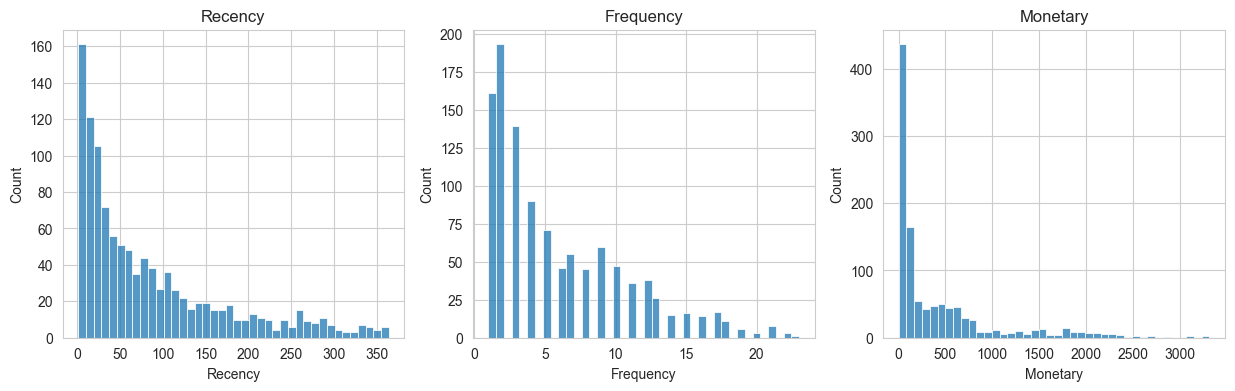

In [55]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for i, col in enumerate(['Recency', 'Frequency', 'Monetary']):
    sns.histplot(rfm[col], bins=40, ax=ax[i])
    ax[i].set_title(col)
plt.show()

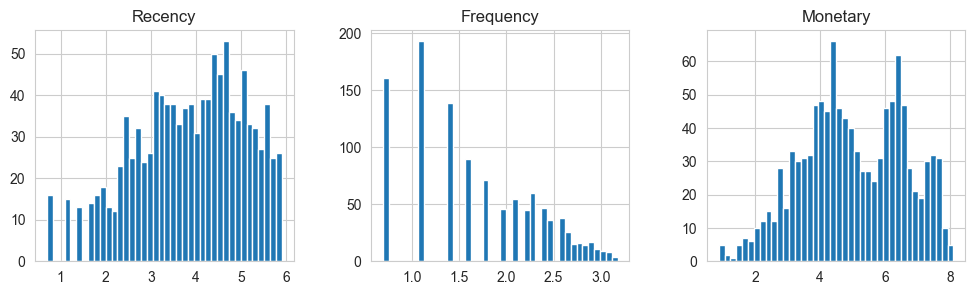

In [56]:
rfm_log = np.log1p(rfm[['Recency', 'Frequency', 'Monetary']])

scaler = StandardScaler()
X = scaler.fit_transform(rfm_log)

# check after log
rfm_log.hist(bins=40, figsize=(12, 3), layout=(1, 3))
plt.show()

In [57]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

print("variance explained:", pca.explained_variance_ratio_)
print("total:", pca.explained_variance_ratio_.sum())

rfm['pca1'] = X_pca[:, 0]
rfm['pca2'] = X_pca[:, 1]

variance explained: [0.78345853 0.19079347]
total: 0.9742519919951377


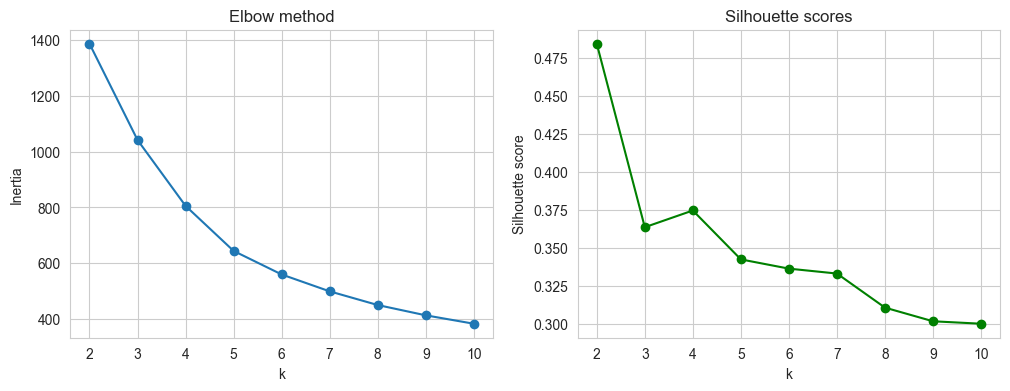

In [58]:
inertia = []
sil = []
k_range = range(2, 11)

for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(X)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X, km.labels_))

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(k_range, inertia, marker='o')
plt.xlabel('k')
plt.ylabel('Inertia')
plt.title('Elbow method')

plt.subplot(1, 2, 2)
plt.plot(k_range, sil, marker='o', color='green')
plt.xlabel('k')
plt.ylabel('Silhouette score')
plt.title('Silhouette scores')

plt.show()

In [59]:
# k chosen from the plots above, change if needed
kmeans = KMeans(n_clusters=4, n_init=10, random_state=42)
rfm['KMeans'] = kmeans.fit_predict(X)

print(rfm['KMeans'].value_counts())
print("silhouette:", silhouette_score(X, rfm['KMeans']))

KMeans
1    396
2    265
3    242
0    198
Name: count, dtype: int64
silhouette: 0.37454809007257167


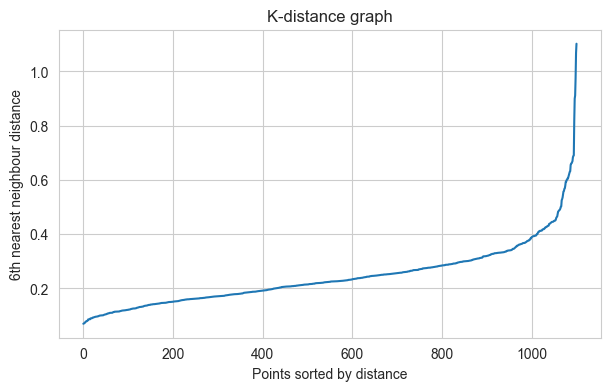

In [60]:
nn = NearestNeighbors(n_neighbors=6)
nn.fit(X)
distances, indices = nn.kneighbors(X)

# distance to the 6th neighbour, sorted
k_dist = np.sort(distances[:, 5])

plt.figure(figsize=(7, 4))
plt.plot(k_dist)
plt.xlabel('Points sorted by distance')
plt.ylabel('6th nearest neighbour distance')
plt.title('K-distance graph')
plt.show()

In [61]:
# eps taken from the elbow of the graph above
dbscan = DBSCAN(eps=0.35, min_samples=6)
rfm['DBSCAN'] = dbscan.fit_predict(X)

print(rfm['DBSCAN'].value_counts())

n_clusters = len(set(rfm['DBSCAN'])) - (1 if -1 in rfm['DBSCAN'].values else 0)
print("clusters found:", n_clusters)
print("noise points:", (rfm['DBSCAN'] == -1).sum())

DBSCAN
 1    724
 0    174
 2    141
-1     56
 3      6
Name: count, dtype: int64
clusters found: 4
noise points: 56


In [62]:
# this takes a minute or so
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
X_tsne = tsne.fit_transform(X)

rfm['tsne1'] = X_tsne[:, 0]
rfm['tsne2'] = X_tsne[:, 1]

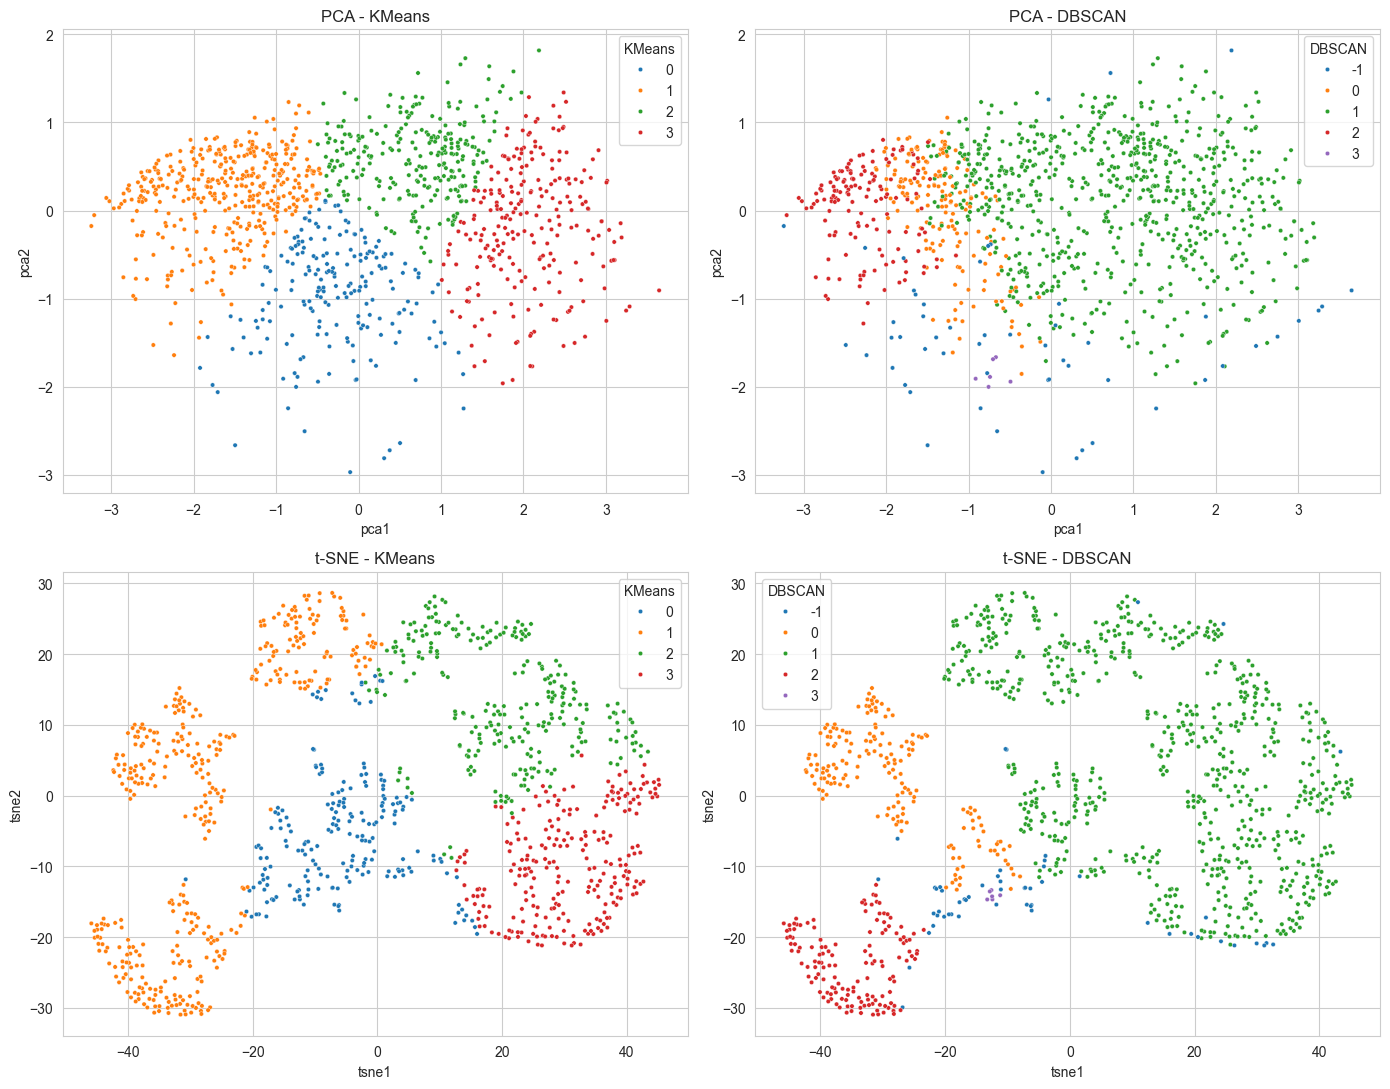

In [63]:
fig, ax = plt.subplots(2, 2, figsize=(14, 11))

sns.scatterplot(x='pca1', y='pca2', hue='KMeans', data=rfm, palette='tab10', s=10, ax=ax[0, 0])
ax[0, 0].set_title('PCA - KMeans')

sns.scatterplot(x='pca1', y='pca2', hue='DBSCAN', data=rfm, palette='tab10', s=10, ax=ax[0, 1])
ax[0, 1].set_title('PCA - DBSCAN')

sns.scatterplot(x='tsne1', y='tsne2', hue='KMeans', data=rfm, palette='tab10', s=10, ax=ax[1, 0])
ax[1, 0].set_title('t-SNE - KMeans')

sns.scatterplot(x='tsne1', y='tsne2', hue='DBSCAN', data=rfm, palette='tab10', s=10, ax=ax[1, 1])
ax[1, 1].set_title('t-SNE - DBSCAN')

plt.tight_layout()
plt.show()

In [64]:
cluster_summary = rfm.groupby('KMeans').agg({
    'CustomerID': 'count',
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': ['mean', 'sum']
}).round(1)

cluster_summary

CustomerID Recency Frequency Monetary          
            count    mean      mean     mean       sum
KMeans                                                
0             198    24.1       3.1     83.6   16560.0
1             396   170.6       2.0     52.2   20674.0
2             265    66.1       7.8    520.3  137890.2
3             242    13.4      12.4   1165.9  282139.6

In [65]:
share = rfm.groupby('KMeans').agg(
    customers=('CustomerID', 'count'),
    revenue=('Monetary', 'sum')
)
share['pct_customers'] = (share['customers'] / share['customers'].sum() * 100).round(1)
share['pct_revenue'] = (share['revenue'] / share['revenue'].sum() * 100).round(1)

share

,customers,revenue,pct_customers,pct_revenue
KMeans,,,,
0,198,16560.01,18.0,3.6
1,396,20674.01,36.0,4.5
2,265,137890.23,24.1,30.2
3,242,282139.60,22.0,61.7


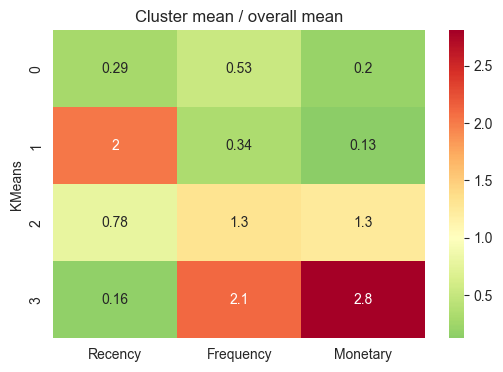

In [66]:
means = rfm.groupby('KMeans')[['Recency', 'Frequency', 'Monetary']].mean()
relative = means / rfm[['Recency', 'Frequency', 'Monetary']].mean()

plt.figure(figsize=(6, 4))
sns.heatmap(relative, annot=True, cmap='RdYlGn_r', center=1)
plt.title('Cluster mean / overall mean')
plt.show()

In [67]:
persona_names = {
    0: 'Champions',            # low recency, high frequency, high spend
    1: 'Lost Customers',       # high recency, low frequency, low spend
    2: 'Loyal Customers',      # medium recency, good frequency
    3: 'New / Occasional'      # low recency, low frequency
}

rfm['Persona'] = rfm['KMeans'].map(persona_names)
rfm['Persona'].value_counts()

Persona
Lost Customers      396
Loyal Customers     265
New / Occasional    242
Champions           198
Name: count, dtype: int64

In [68]:
actions = {
    'Champions': 'VIP rewards, early access to new products, referral program',
    'Loyal Customers': 'Loyalty points, cross-sell and upsell, bundle deals',
    'New / Occasional': 'Welcome emails, discount on second purchase, product recommendations',
    'Lost Customers': 'Win-back email with a limited offer, then stop spending ad money on them'
}

persona_table = rfm.groupby('Persona')[['Recency', 'Frequency', 'Monetary']].mean().round(1)
persona_table['Action'] = persona_table.index.map(actions)

pd.set_option('display.max_colwidth', 100)
persona_table

,Recency,Frequency,Monetary,Action
Persona,,,,
Champions,24.1,3.1,83.6,"VIP rewards, early access to new products, referral program"
Lost Customers,170.6,2.0,52.2,"Win-back email with a limited offer, then stop spending ad money on them"
Loyal Customers,66.1,7.8,520.3,"Loyalty points, cross-sell and upsell, bundle deals"
New / Occasional,13.4,12.4,1165.9,"Welcome emails, discount on second purchase, product recommendations"


In [69]:
noise = rfm[rfm['DBSCAN'] == -1]
print("number of noise points:", len(noise))
print(noise[['Recency', 'Frequency', 'Monetary']].mean())

# biggest spenders among them
noise.sort_values('Monetary', ascending=False).head(10)

number of noise points: 56
Recency       31.017857
Frequency      4.232143
Monetary     298.428750
dtype: float64


,CustomerID,Recency,Frequency,Monetary,pca1,pca2,KMeans,DBSCAN,tsne1,tsne2,Persona
264,12286.0,87,21,3133.98,2.188687,1.818366,2,-1,43.366463,6.207657,Loyal Customers
597,12646.0,1,21,2664.41,3.645677,-0.906770,3,-1,32.578102,-21.047066,New / Occasional
437,12472.0,1,15,2227.32,3.287930,-1.089486,3,-1,31.508999,-20.848261,New / Occasional
707,12767.0,1,17,1517.52,3.245501,-1.136055,3,-1,31.151548,-21.184793,New / Occasional
575,12619.0,1,13,1468.86,3.005442,-1.252641,3,-1,29.940943,-20.896130,New / Occasional
498,12538.0,1,9,845.27,2.486478,-1.537785,3,-1,24.218414,-20.598671,New / Occasional
60,12067.0,3,6,830.17,1.878317,-1.204469,3,-1,21.807669,-17.244385,New / Occasional
885,12963.0,1,14,643.23,2.747385,-1.432255,3,-1,26.372633,-21.178326,New / Occasional
176,12189.0,163,11,559.97,0.721609,1.561928,2,-1,24.622337,24.261427,Loyal Customers
514,12556.0,1,7,502.92,2.083141,-1.765539,3,-1,20.527802,-19.991795,New / Occasional


In [70]:
rfm.to_csv('rfm_segments.csv', index=False)